In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder, RobustScaler, PolynomialFeatures
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, RandomizedSearchCV, learning_curve

from sklearn.linear_model import Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor

from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

#### Data Observation, Cleaning

In [2]:
df = pd.read_csv('car.csv')

df

,MODEL,MAKE,MODEL.1,VEHICLE CLASS,ENGINE_SIZE,CYLINDERS,TRANSMISSION,FUEL,FUEL_CONSUMPTION*,Unnamed: 9,Unnamed: 10,Unnamed: 11,CO2_EMISSIONS
0,2001,ACURA,1.7EL,COMPACT,1.7,4,A4,X,9.3,7.2,8.3,34,191
1,2001,ACURA,1.7EL,COMPACT,1.7,4,M5,X,8.9,7.4,8.3,34,191
2,2001,ACURA,3.2CL,COMPACT,3.2,6,AS5,Z,13.7,8.8,11.5,25,265
3,2001,ACURA,3.2TL,MID-SIZE,3.2,6,AS5,Z,13.8,8.8,11.6,24,267
4,2001,ACURA,3.5RL,MID-SIZE,3.5,6,A4,Z,15.0,10.9,13.1,22,301
...,...,...,...,...,...,...,...,...,...,...,...,...,...
674,2001,VOLVO,V70 T5 WAGON TURBO,STATION WAGON - MID-SIZE,2.3,5,M5,Z,13.0,9.3,11.3,25,260
675,2001,VOLVO,V70 WAGON,STATION WAGON - MID-SIZE,2.4,5,A5,Z,12.8,9.3,11.2,25,258
676,2001,VOLVO,V70 WAGON,STATION WAGON - MID-SIZE,2.4,5,M5,Z,12.5,9.3,11.0,26,253
677,2001,VOLVO,V70 WAGON AWD TURBO,STATION WAGON - MID-SIZE,2.4,5,AS5,Z,14.4,10.3,12.5,23,288


In [3]:
# standardize columns

df.columns = df.columns.str.strip().str.lower().str.replace(' ', '_').str.replace(':', '').str.replace('*', '')

In [4]:
df.columns

Index(['model', 'make', 'model.1', 'vehicle_class', 'engine_size', 'cylinders',
       'transmission', 'fuel', 'fuel_consumption', 'unnamed_9', 'unnamed_10',
       'unnamed_11', 'co2_emissions'],
      dtype='object')

In [5]:
df.rename(columns = {'model': 'year',
                     'make' : 'maker',
                     'model.1': 'model',
                    'unnamed_9': 'fuel_consumption2',
                    'unnamed_10': 'fuel_consumption3', 
                    'unnamed_11': 'fuel_consumption4'}, inplace = True)
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 679 entries, 0 to 678
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   year               679 non-null    int64  
 1   maker              679 non-null    object 
 2   model              679 non-null    object 
 3   vehicle_class      679 non-null    object 
 4   engine_size        679 non-null    float64
 5   cylinders          679 non-null    int64  
 6   transmission       679 non-null    object 
 7   fuel               679 non-null    object 
 8   fuel_consumption   679 non-null    float64
 9   fuel_consumption2  679 non-null    float64
 10  fuel_consumption3  679 non-null    float64
 11  fuel_consumption4  679 non-null    int64  
 12  co2_emissions      679 non-null    int64  
dtypes: float64(4), int64(4), object(5)
memory usage: 69.1+ KB


In [6]:
df['vehicle_class'].value_counts()

vehicle_class
COMPACT                     145
PICKUP TRUCK - STANDARD     101
SUV                          98
MID-SIZE                     82
SUBCOMPACT                   62
TWO-SEATER                   31
STATION WAGON - MID-SIZE     31
FULL-SIZE                    30
VAN - CARGO                  23
VAN - PASSENGER              18
MINIVAN                      17
MINICOMPACT                  17
STATION WAGON - SMALL        12
PICKUP TRUCK - SMALL         12
Name: count, dtype: int64

In [7]:
df.describe()

,year,engine_size,cylinders,fuel_consumption,fuel_consumption2,fuel_consumption3,fuel_consumption4,co2_emissions
count,679.0,679.000000,679.000000,679.000000,679.000000,679.000000,679.000000,679.000000
mean,2001.0,3.252577,5.798233,14.591900,10.613844,12.802798,23.107511,293.656848
std,0.0,1.203751,1.531073,3.025654,2.357724,2.685590,5.308083,60.372456
min,2001.0,1.000000,3.000000,4.900000,4.000000,4.500000,14.000000,104.000000
25%,2001.0,2.200000,4.000000,12.700000,9.000000,11.000000,19.000000,253.000000
50%,2001.0,3.000000,6.000000,14.300000,10.100000,12.300000,23.000000,283.000000
75%,2001.0,4.200000,6.000000,16.650000,12.500000,14.850000,26.000000,340.000000
max,2001.0,8.000000,12.000000,23.200000,18.000000,20.800000,63.000000,478.000000


In [8]:
df.isnull().sum()

year                 0
maker                0
model                0
vehicle_class        0
engine_size          0
cylinders            0
transmission         0
fuel                 0
fuel_consumption     0
fuel_consumption2    0
fuel_consumption3    0
fuel_consumption4    0
co2_emissions        0
dtype: int64

In [9]:
df.duplicated().sum()

np.int64(0)

#### Data Visualization

Text(0, 0.5, 'Fuel Consumption')

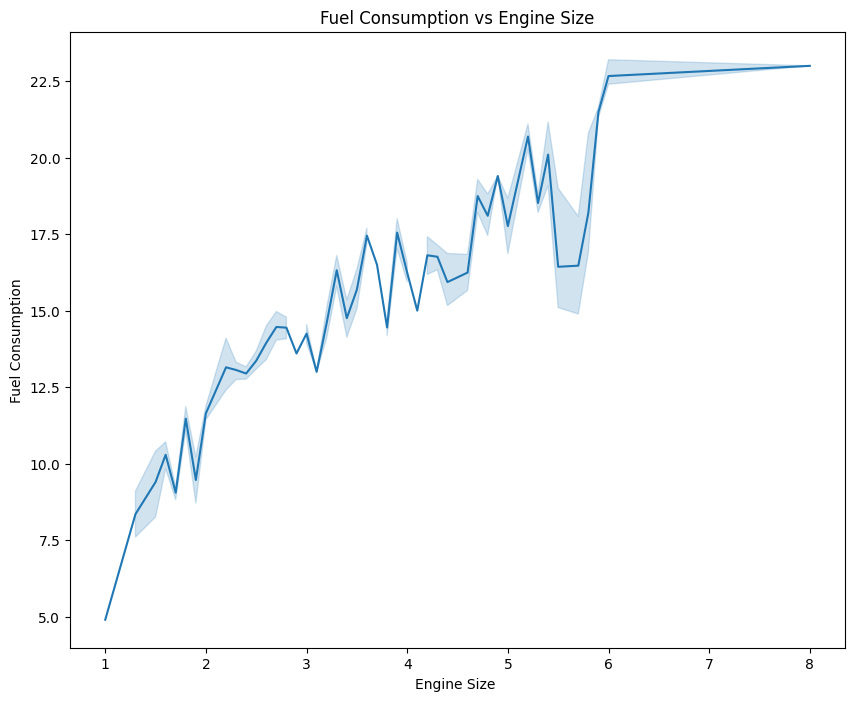

In [10]:
plt.figure(figsize = (10, 8))
sns.lineplot(x = 'engine_size', y = 'fuel_consumption', data = df)
plt.title('Fuel Consumption vs Engine Size')
plt.xlabel('Engine Size ')
plt.ylabel('Fuel Consumption')


Text(0, 0.5, 'Manufacturer')

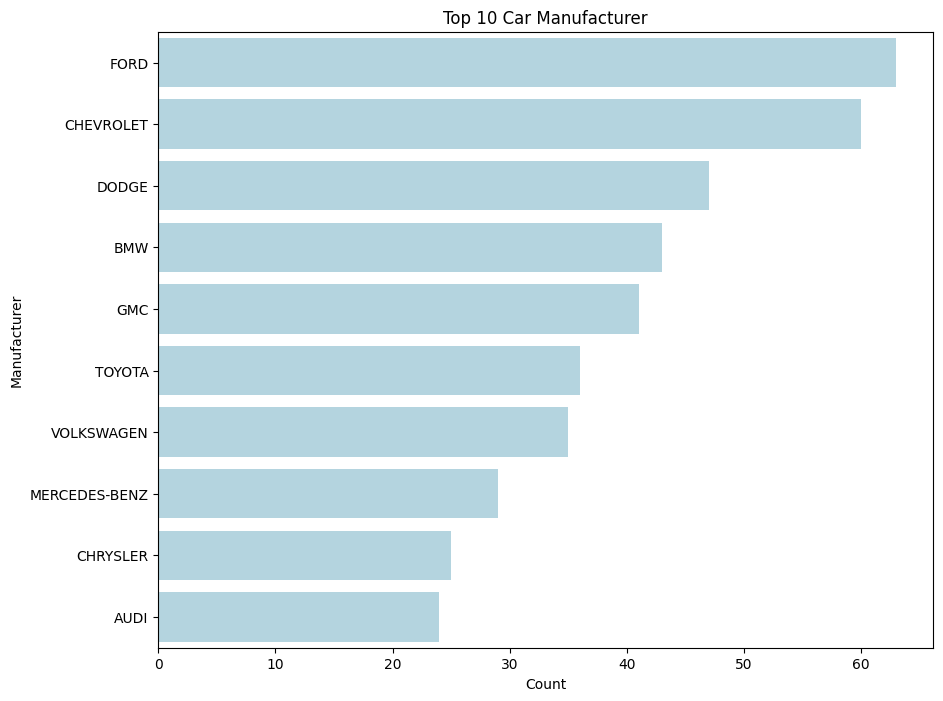

In [11]:
plt.figure(figsize = (10, 8))
sns.countplot(y = 'maker', 
            data = df,
            order = df['maker'].value_counts().nlargest(10).index,
            color = 'lightblue')
plt.title('Top 10 Car Manufacturer')
plt.xlabel('Count')
plt.ylabel('Manufacturer')

Text(0, 0.5, 'Class')

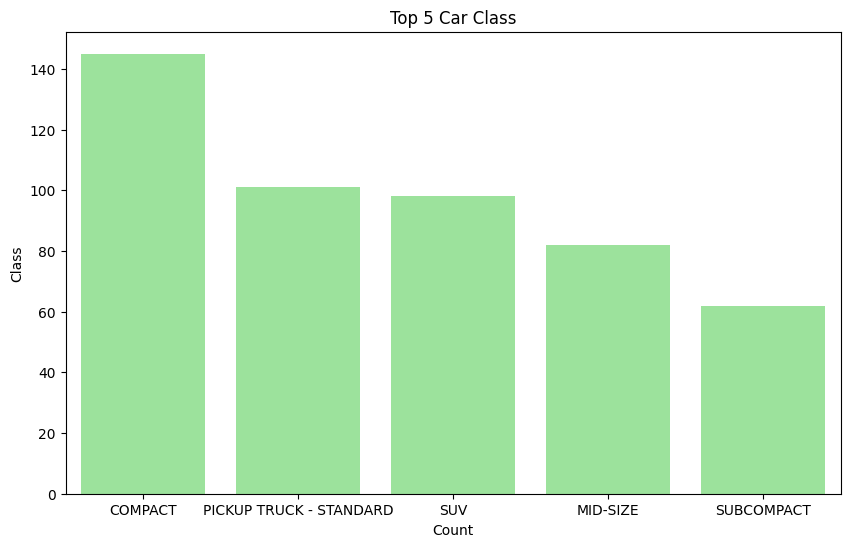

In [12]:
plt.figure(figsize = (10, 6))
sns.countplot(x = 'vehicle_class', 
            data = df,
            order = df['vehicle_class'].value_counts().nlargest(5).index,
            color = 'lightgreen')
plt.title('Top 5 Car Class')
plt.xlabel('Count')
plt.ylabel('Class')

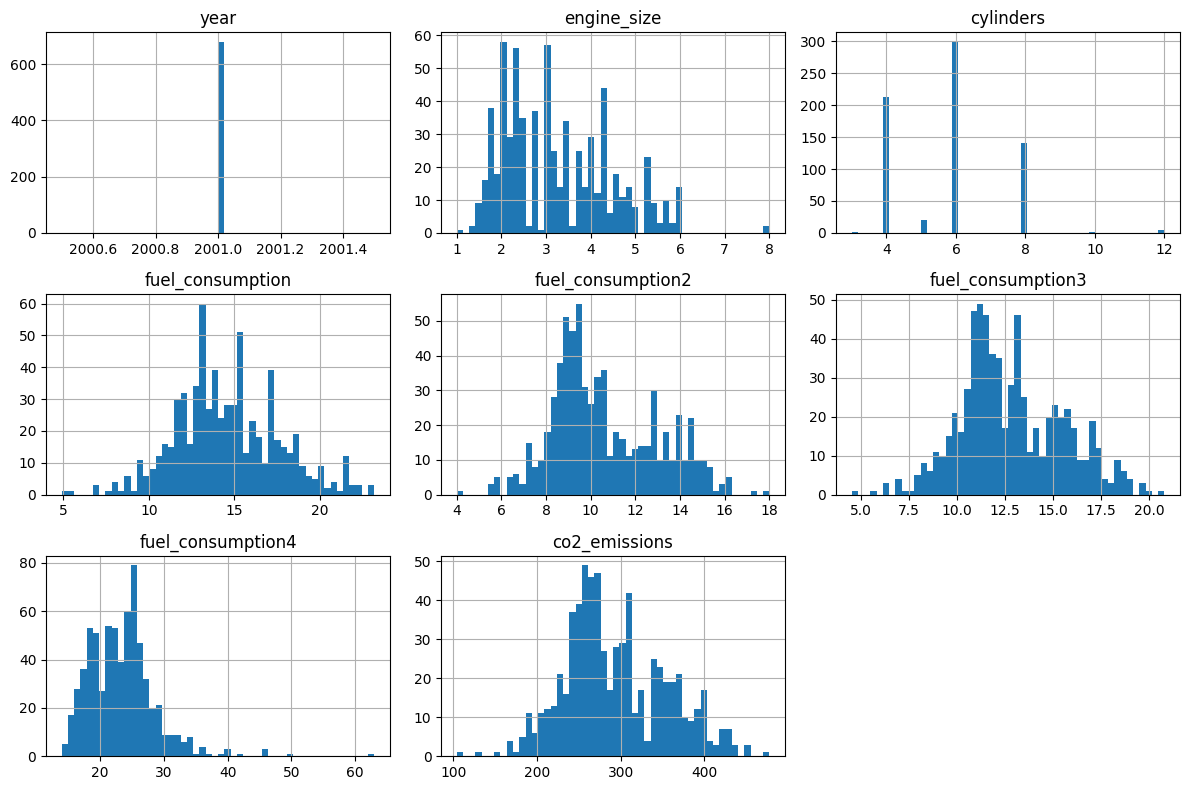

In [13]:
df.hist(bins = 50, figsize = (12, 8))
plt.tight_layout()

C:\Users\Louis Bernal\AppData\Local\Temp\ipykernel_1868\4253048660.py:5: UserWarning: Dataset has 0 variance; skipping density estimate. Pass `warn_singular=False` to disable this warning.
  sns.kdeplot(df[column], fill=True, color="skyblue")


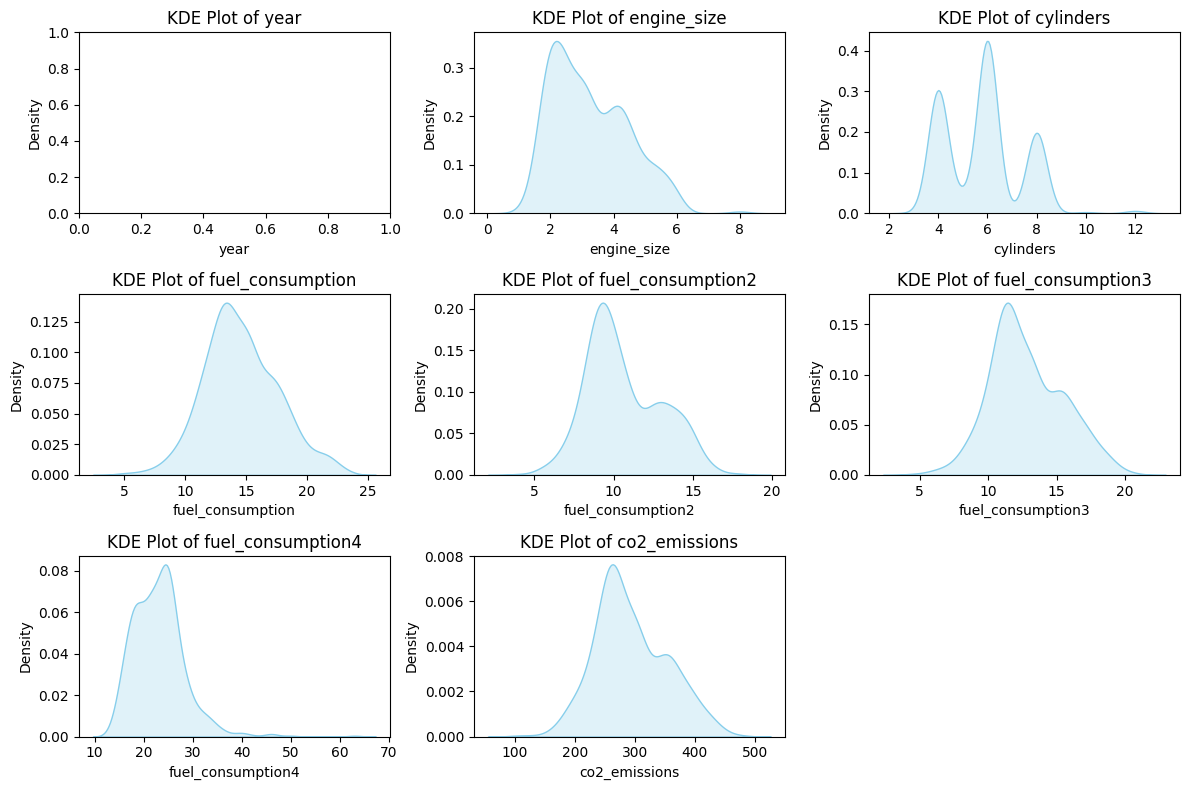

In [14]:
# KDE Plot for each numerical feature to check distribution and skewness
plt.figure(figsize=(12, 8))
for idx, column in enumerate(df.select_dtypes(exclude='object').columns, 1):
    plt.subplot(3, 3, idx)
    sns.kdeplot(df[column], fill=True, color="skyblue")
    plt.title(f"KDE Plot of {column}")
    plt.xlabel(column)
    plt.ylabel("Density")
plt.tight_layout()
plt.show()


Text(0.5, 1.0, 'Correlation Matrix')

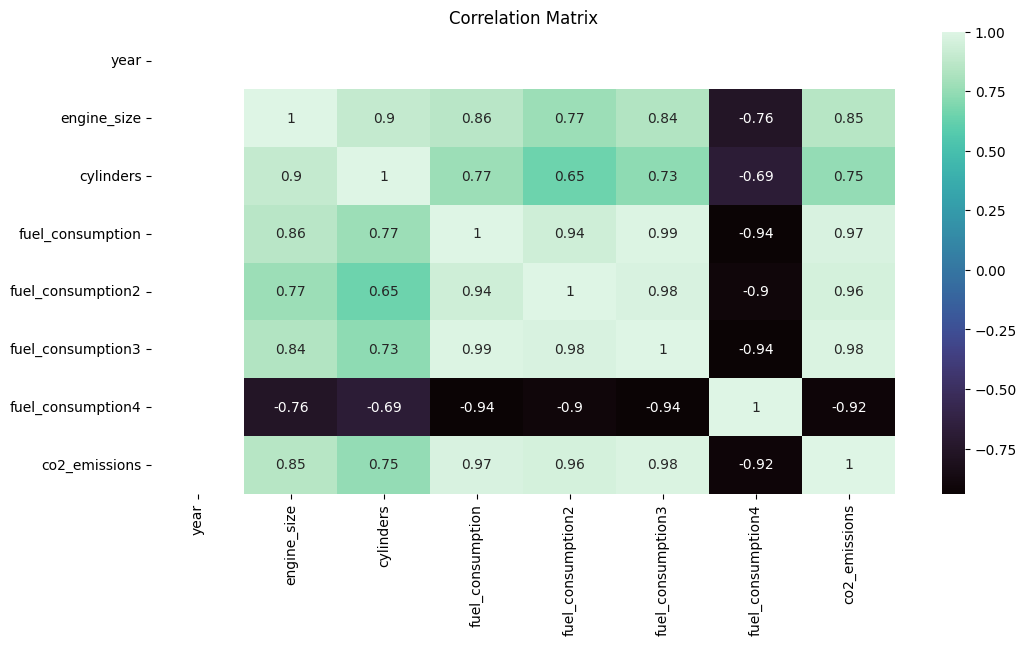

In [15]:
num_df = df.select_dtypes(exclude = 'object')
df_corr = num_df.corr()

plt.figure(figsize = (12, 6))
sns.heatmap(df_corr, annot = True, cmap = 'mako')
plt.title('Correlation Matrix')

#### Data Preprocessing

In [16]:
# drop unnecessary and redundant columns

df.drop(['year', 'fuel_consumption2', 'fuel_consumption3', 'fuel_consumption4'], axis=1, inplace=True)

In [17]:
categorical_cols = df.select_dtypes('object').columns

# apply LabelEncoder to each categorical column
for col in categorical_cols:
    df[col] = LabelEncoder().fit_transform(df[col])

In [18]:
df.columns

Index(['maker', 'model', 'vehicle_class', 'engine_size', 'cylinders',
       'transmission', 'fuel', 'fuel_consumption', 'co2_emissions'],
      dtype='object')

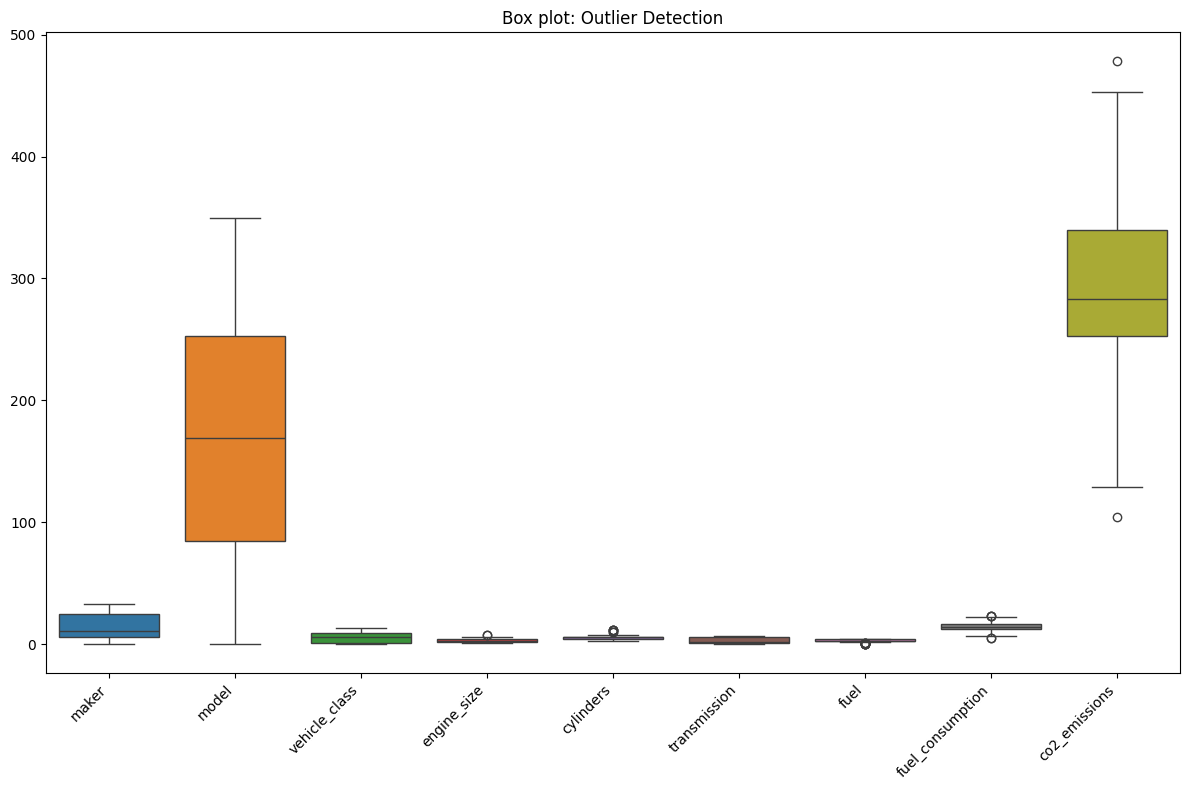

In [19]:
plt.figure(figsize=(12, 8))
sns.boxplot(data=df[['maker', 'model', 'vehicle_class', 'engine_size', 'cylinders',
       'transmission', 'fuel', 'fuel_consumption', 'co2_emissions']])

plt.title('Box plot: Outlier Detection')
plt.xticks(rotation=45, ha='right')  
plt.tight_layout()  

plt.show()


In [20]:
# Interquartile Range (IQR) function to remove outliars

data_numeric = df.select_dtypes(exclude='object')

for col in data_numeric.columns:
    q1 = data_numeric[col].quantile(0.25)
    q3 = data_numeric[col].quantile(0.75)
    iqr = q3 - q1
    low = q1 - (1.5 * iqr)
    high = q3 + (1.5 * iqr)

    # Count outliers
    outliers = ((data_numeric[col] > high) | (data_numeric[col] < low)).sum()
    total = data_numeric.shape[0]
    print(f"Total outliers in {col} are: {outliers} - {round(100 * (outliers / total), 2)}%")

    if outliers > 0:
        # Filter data to exclude outliers
        df = df.loc[(df[col] <= high) & (df[col] >= low)]

Total outliers in maker are: 0 - 0.0%
Total outliers in model are: 0 - 0.0%
Total outliers in vehicle_class are: 0 - 0.0%
Total outliers in engine_size are: 2 - 0.29%
Total outliers in cylinders are: 6 - 0.88%
Total outliers in transmission are: 0 - 0.0%
Total outliers in fuel are: 10 - 1.47%
Total outliers in fuel_consumption are: 5 - 0.74%
Total outliers in co2_emissions are: 2 - 0.29%


In [21]:
# split df into x (independent), y (dependent) variables
x = df.drop(['co2_emissions'], axis = 1).values
y = df['co2_emissions'].values

In [22]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.2, random_state = 42)

In [23]:
# robust scaler less sensitive to skewed / data with outliers, ensures stable features
rc = RobustScaler()
x_train = rc.fit_transform(x_train)
x_test= rc.transform(x_test)

#### Data Modeling, Prediction
##### Model Overview

In [24]:
# implement ml models (regressors)
regressors = {
    'Ridge Regression': Ridge(),
    'KNN': KNeighborsRegressor(),
    'SVM': SVR(),
    'RandomForest': RandomForestRegressor(),
    'XGBoost': XGBRegressor()
}

In [25]:
# check accuracy using cross_val_score
for key, regressor in regressors.items():
    regressor.fit(x_train, y_train)
    training_score = cross_val_score(regressor, x_train, y_train, cv = 5)
    print(f"{regressor.__class__.__name__} Training Score: {round(training_score.mean() * 100, 2)}%")

Ridge Training Score: 97.6%
KNeighborsRegressor Training Score: 91.32%
SVR Training Score: 69.05%
RandomForestRegressor Training Score: 98.21%
XGBRegressor Training Score: 98.45%


##### Hyperparameter Tuning

In [26]:
# KNN parameters
knn_params = {
    'n_neighbors': [5, 10, 20, 50, 70],  # Number of neighbors to consider
    'weights': ['uniform', 'distance'],  # Weight function used in prediction
    'algorithm': ['auto', 'ball_tree', 'kd_tree', 'brute'],  # Algorithm for nearest neighbors
    'leaf_size': [30, 40, 50, 60],  # Leaf size for BallTree and KDTree
    'p': [1, 2]  # Power parameter for Minkowski distance (1 for Manhattan, 2 for Euclidean)
}

# GridSearchCV for KNN
knn_grid = GridSearchCV(KNeighborsRegressor(), knn_params, cv=5, n_jobs=-1)
knn_grid.fit(x_train, y_train)

# New KNN model with best parameters
knn = knn_grid.best_estimator_

# Show best parameters from GridSearchCV
print(f'Best Parameters for KNN: {knn_grid.best_params_}')

Best Parameters for KNN: {'algorithm': 'auto', 'leaf_size': 30, 'n_neighbors': 5, 'p': 1, 'weights': 'distance'}


c:\Users\Louis Bernal\AppData\Local\Programs\Python\Python312\Lib\site-packages\numpy\ma\core.py:2846: RuntimeWarning: invalid value encountered in cast
  _data = np.array(data, dtype=dtype, copy=copy,


In [27]:
# check fine-tuned accuracy using cross_val_score
knn_training_score = cross_val_score(knn, x_train, y_train, cv = 5)
print(f'{knn.__class__.__name__} Tuned Training SCore: {round(knn_training_score.mean() * 100, 2)}%')

KNeighborsRegressor Tuned Training SCore: 94.27%


In [28]:
# SVM  parameters
svm_params = {
    'C': [0.1, 1, 10, 100],
    'kernel': ['linear', 'rbf', 'poly', 'sigmoid'],
    'gamma': ['scale', 'auto']
}

svr_grid = GridSearchCV(SVR(), svm_params, cv = 5, n_jobs = -1)
svr_grid.fit(x_train, y_train)

# new model with best parameters
svr = svr_grid.best_estimator_

# show the best parameters found by GridSearchCV
print(f"Best parameters for SVM: {svr_grid.best_params_}")

Best parameters for SVM: {'C': 100, 'gamma': 'auto', 'kernel': 'rbf'}


In [29]:
# check fine-tuned accuracy using cross_val_score
svm_training_score = cross_val_score(svr, x_train, y_train, cv=5)
print(f"{svr.__class__.__name__} Tuned Training Score: {round(svm_training_score.mean() * 100, 2)}%")

SVR Tuned Training Score: 98.59%


In [ ]:
# xgb parameters
xg_params = {
    'objective': ['reg:squarederror'],
    'eta': [0.05],  # Try a range of learning rates
    'alpha': [7, 8, 9],  # Include more values for L1 regularization
    'lambda': [7, 8, 9],  # Include more values for L2 regularization
    'gamma': [7, 8, 9], # regularization
    'max_depth': [1, 2],  # Test a range of tree depths
    'subsample': [0.5],  # Use subsampling to prevent overfitting
    'colsample_bytree': [0.6, 0.8],  # Control feature sampling
    'eval_metric': ['rmse']
}

xg_grid = GridSearchCV(XGBRegressor(), xg_params, cv = 5, n_jobs = -1)
xg_grid.fit(x_train, y_train)

# new xgboost model
xgb = xg_grid.best_estimator_

print(f'Best parameters for XGB: {xg_grid.best_params_}')

NameError: name 'GridSearchCV' is not defined

In [51]:
xgb__training__score = cross_val_score(xgb, x_train, y_train, cv = 5)
print(f'{xgb.__class__.__name__} Tuned Training Score: {round(xgb__training__score.mean()* 100)}')

XGBRegressor Tuned Training Score: 96


#### Evaluation

In [52]:
# Define the regressors
new_regressors = {
    'Ridge Regression': Ridge(),
    'KNN': knn, # new model fit with best_estimator_
    'SVM': svr, # another model fit with best_estimator_
    'Random Forest': RandomForestRegressor(),
    'XGBoost': xgb
}

# Fit and predict for each regressor
predictions = {}
for name, regressor in new_regressors.items():
    regressor.fit(x_train, y_train)
    predictions[name] = regressor.predict(x_test)

# Calculate and display metrics
metrics = []
for name, y_pred in predictions.items():
    r2 = r2_score(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    mae = mean_absolute_error(y_test, y_pred)
    metrics.append([r2, rmse, mae])

model_names = ['Ridge Regression', 'KNN', 'SVM', 'Random Forest', 'XGBoost']
results_df = pd.DataFrame(metrics, columns=['R2', 'RMSE', 'MAE'], index=model_names)
results_df = results_df.sort_values(ascending=False, by='R2')
print(results_df)

                        R2       RMSE       MAE
Random Forest     0.988833   6.008129  4.158864
SVM               0.988467   6.105800  4.802848
Ridge Regression  0.968630  10.070120  7.023294
XGBoost           0.963718  10.829883  8.098605
KNN               0.939512  13.983321  9.447913


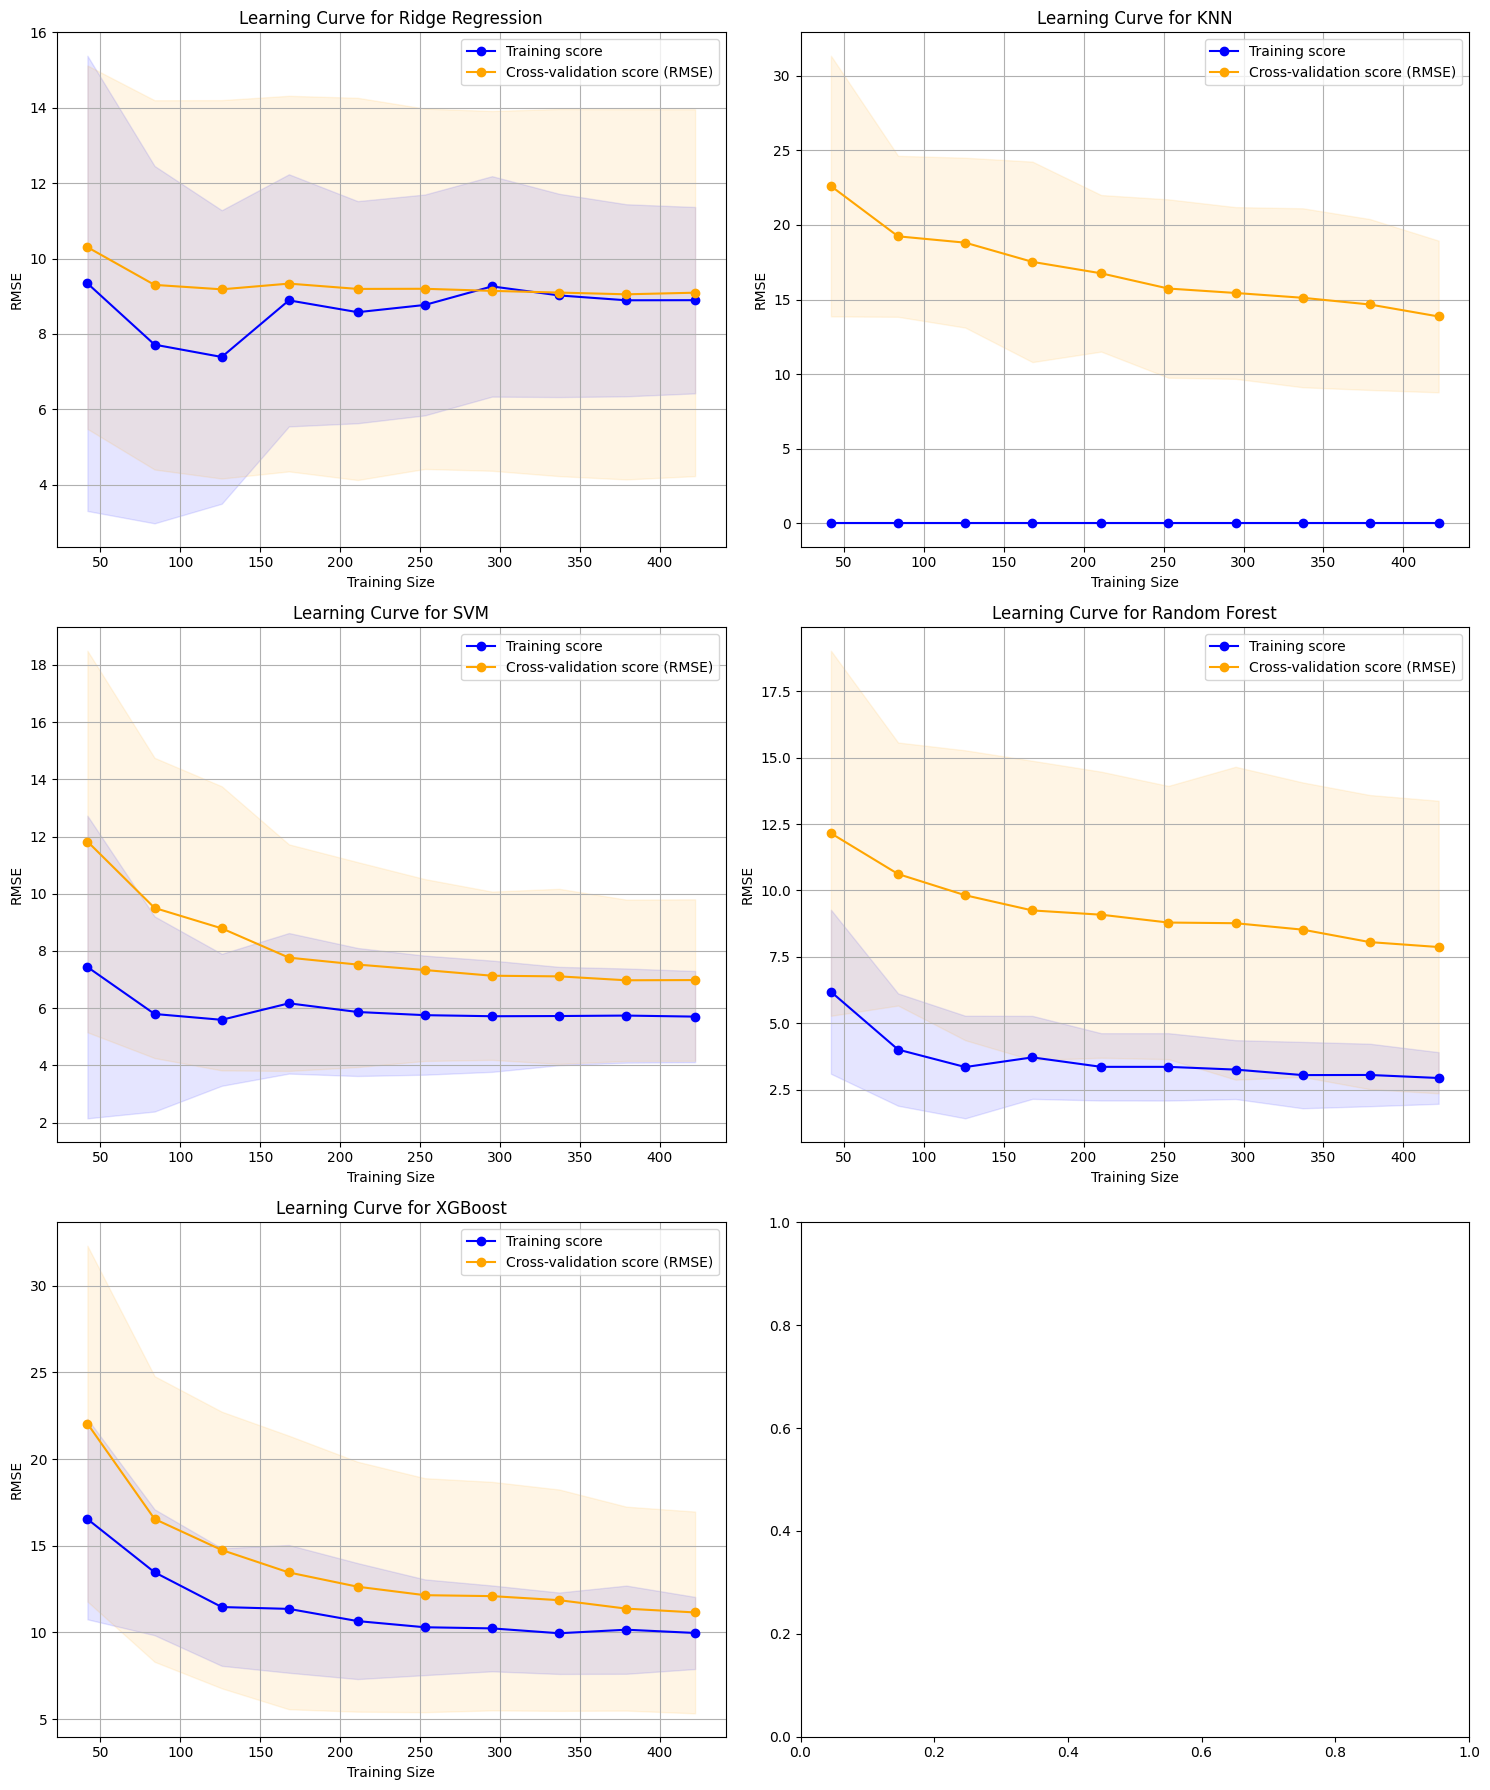

In [53]:
# Define a function to plot learning curves
def plot_learning_curve(model, x, y, model_name, ax):
    train_sizes, train_scores, val_scores = learning_curve(
        model, x, y, cv=5, n_jobs=-1,
        train_sizes=np.linspace(0.1, 1.0, 10),
        scoring='neg_mean_squared_error'
    )
    
    # Calculate the mean and standard deviation for training and validation scores
    train_scores_mean = np.sqrt(-train_scores.mean(axis=1))
    val_scores_mean = np.sqrt(-val_scores.mean(axis=1))
    train_scores_std = np.sqrt(train_scores.std(axis=1))
    val_scores_std = np.sqrt(val_scores.std(axis=1))

    # Plotting
    ax.plot(train_sizes, train_scores_mean, 'o-', color='blue', label='Training score')
    ax.plot(train_sizes, val_scores_mean, 'o-', color='orange', label='Cross-validation score (RMSE)')
    
    # Plot the confidence intervals
    ax.fill_between(train_sizes, 
                    train_scores_mean - train_scores_std,
                    train_scores_mean + train_scores_std, 
                    alpha=0.1, color='blue')
    ax.fill_between(train_sizes, 
                    val_scores_mean - val_scores_std,
                    val_scores_mean + val_scores_std, 
                    alpha=0.1, color='orange')
    
    ax.set_title(f'Learning Curve for {model_name}')
    ax.set_xlabel('Training Size')
    ax.set_ylabel('RMSE')
    ax.legend(loc='best')
    ax.grid()

# Plotting learning curves for all regressors
fig, axes = plt.subplots(3, 2, figsize=(15, 18))
axes = axes.flatten()

for i, (model_name, model) in enumerate(new_regressors.items()):
    plot_learning_curve(model, x_train, y_train, model_name, axes[i])

plt.tight_layout()
plt.show()